
# PRDM9 G4 enrichment main figure — production notebook

This notebook reproduces the **old-style G4 enrichment statistics exactly**, with only the following extensions:

- run the analysis twice:
  - **datasetA_matched** (length + GC + entropy matched background)
  - **datasetB_global** (length-only global background)
- restrict the primary analysis and figure to **`covfrac` only**
- render a publication-ready **2×2 main figure**:
  - **left column**: dataset A / matched background
  - **right column**: dataset B / global background
  - **top row**: supported G4 loci (overlap with experimental HEK293 G4 track)
  - **bottom row**: unsupported G4 loci

The statistical flow is intentionally preserved from the legacy notebook:

1. assign **global score quartiles Q1–Q4** from `pqsfinder_hg38.bed`
2. define overlapping canonical track families (`short`, `medium`, `long`) from the TXT files
3. define `noncanon` as the residual set
4. build per-window features on the expanded overlapping-track representation
5. compare **PRDM9 vs background** using:
   - exact **Welch t-test** (reference)
   - **BG-null Monte Carlo** (primary enrichment significance)
   - **POS-null Monte Carlo** (internal variability diagnostic)
6. define final significance as:

\[
\mathrm{FDR}_{\mathrm{final}} = \max\left(\mathrm{BH\!-\!FDR}_{\mathrm{exact}}, \mathrm{BH\!-\!FDR}_{\mathrm{MC\_BG}}\right)
\]

Effect size is:

\[
\Delta = \mathrm{mean}(\text{PRDM9 covfrac}) - \mathrm{mean}(\text{background covfrac})
\]

FG/BG window counts shown in the panel labels are the numbers of windows with at least one overlapping locus in that track-group.


In [1]:

# Core setup
import os
import gc
import json
import math
import logging
from pathlib import Path
from concurrent.futures import ProcessPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from tqdm.auto import tqdm
import pyranges as pr
import pysam
from scipy.stats import ttest_ind

from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich.logging import RichHandler

# ------------------------------------------------------------------
# Configuration
# ------------------------------------------------------------------
N_WORKERS = 64
N_ITERS = 200_000
CHUNK_ITERS = 1000
RANDOM_SEED = 31
SLACK_BP = 3

CANONICAL = {f"chr{i}" for i in range(1, 23)} | {"chrX", "chrY"}

SAMPLING_DIR = Path("data_prdm9_sampling_production")
PRDM9_BED = SAMPLING_DIR / "prdm9_filtered.bed"
DATASETA_BED = SAMPLING_DIR / "datasetA_matched.len_gc_entropy.bed"
DATASETB_BED = SAMPLING_DIR / "datasetB_global.length_only.bed"

G4_SCORE_BED = Path("g4/pqsfinder_hg38.bed")
G4_SHORT_TXT = Path("g4/G4s_short_pqsfinder_hg38.txt")
G4_MEDIUM_TXT = Path("g4/G4s_median_pqsfinder_hg38.txt")
G4_LONG_TXT = Path("g4/G4s_long_pqsfinder_hg38.txt")
G4_EXPERIMENTAL_BED = Path("g4/HEK293_G4s_hg38.bed")
FASTA_PATH = Path("hg38.fa")

OUTDIR = Path("data_prdm9_g4_enrichment_main_figure_production")
FIGDIR = OUTDIR / "figures"
TABDIR = OUTDIR / "tables"
FEATDIR = OUTDIR / "features"
METADIR = OUTDIR / "metadata"
LOGDIR = OUTDIR / "logs"
for p in [OUTDIR, FIGDIR, TABDIR, FEATDIR, METADIR, LOGDIR]:
    p.mkdir(parents=True, exist_ok=True)

WINDOW_FEATURES_A = FEATDIR / "g4seq_oldstyle_covfrac_features.datasetA_matched.parquet"
WINDOW_FEATURES_B = FEATDIR / "g4seq_oldstyle_covfrac_features.datasetB_global.parquet"
RESULTS_TSV = TABDIR / "g4seq_oldstyle_covfrac_enrichment.datasetA_vs_datasetB.tsv"
ANNOTATED_G4_TSV = TABDIR / "g4_loci_annotated_for_enrichment.tsv"
SUMMARY_TSV = TABDIR / "g4_enrichment_panel_summary.tsv"
FIG_PNG = FIGDIR / "Figure_G4_main_2x2_datasetA_vs_datasetB.covfrac_only.png"
FIG_PDF = FIGDIR / "Figure_G4_main_2x2_datasetA_vs_datasetB.covfrac_only.pdf"
META_JSON = METADIR / "run_metadata.json"

# Keep external thread usage controlled
for env_var in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[env_var] = "1"

console = Console()

logger = logging.getLogger("prdm9_g4_enrichment_main")
logger.setLevel(logging.INFO)
logger.handlers.clear()

rich_handler = RichHandler(console=console, rich_tracebacks=True, show_path=False, markup=True)
rich_handler.setFormatter(logging.Formatter("%(message)s"))
logger.addHandler(rich_handler)

file_handler = logging.FileHandler(LOGDIR / "prdm9_g4_enrichment_main.log", mode="w")
file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(file_handler)

mpl.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 320,
    "font.size": 11,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.labelsize": 9,
    "ytick.labelsize": 8,
    "legend.fontsize": 9,
    "grid.alpha": 0.20,
    "axes.grid": False,
})

PALETTE = {
    "datasetA_matched": {
        "sig_1e3": "#CB181D",
        "sig_1e2": "#FB6A4A",
        "sig_5e2": "#FCAE91",
        "ns": "#BDBDBD",
        "accent": "#A50F15",
    },
    "datasetB_global": {
        "sig_1e3": "#08519C",
        "sig_1e2": "#4292C6",
        "sig_5e2": "#9ECAE1",
        "ns": "#BDBDBD",
        "accent": "#084594",
    },
}

console.print(Panel.fit(
    f"[bold]PRDM9 G4 main enrichment figure[/bold]\n"
    f"Workers: {N_WORKERS}\n"
    f"Monte Carlo iterations: {N_ITERS:,}\n"
    f"Chunk size: {CHUNK_ITERS:,}\n"
    f"SLACK_BP: {SLACK_BP}\n"
    f"Output directory: {OUTDIR}",
    border_style="cyan"
))

# ------------------------------------------------------------------
# Helper functions
# ------------------------------------------------------------------
def read_bed3(path, set_name=None):
    df = pd.read_csv(path, sep="\t", header=None, usecols=[0, 1, 2], names=["Chromosome", "Start", "End"])
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    df = df[df["Chromosome"].isin(CANONICAL)].copy().reset_index(drop=True)
    if set_name is not None:
        df["set"] = set_name
    return df

def read_pqsfinder_bed(path):
    df = pd.read_csv(
        path,
        sep="\t",
        header=None,
        usecols=[0, 1, 2, 3, 4, 5],
        names=["Chromosome", "Start", "End", "Name", "Score", "Strand"],
    )
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    df["Score"] = pd.to_numeric(df["Score"], errors="coerce").fillna(0.0).astype(np.float64)
    df = df[df["Chromosome"].isin(CANONICAL)].copy().reset_index(drop=True)
    return df

def read_pqs_txt_track(path):
    df = pd.read_csv(path, sep="\t", header=0)
    rename = {}
    if "seqnames" in df.columns:
        rename["seqnames"] = "Chromosome"
    if "start" in df.columns:
        rename["start"] = "Start"
    if "end" in df.columns:
        rename["end"] = "End"
    df = df.rename(columns=rename)
    keep = ["Chromosome", "Start", "End"]
    if "sequence" in df.columns:
        keep.append("sequence")
    df = df[keep].copy()
    df["Chromosome"] = df["Chromosome"].astype(str)
    df["Start"] = df["Start"].astype(np.int64)
    df["End"] = df["End"].astype(np.int64)
    df = df[df["Chromosome"].isin(CANONICAL)].copy().reset_index(drop=True)
    if "sequence" in df.columns:
        df["sequence"] = df["sequence"].astype(str).str.upper()
    else:
        df["sequence"] = np.nan
    return df

def assign_quartiles_by_rank(values):
    v = np.asarray(values, dtype=np.float64)
    order = np.argsort(v, kind="mergesort")
    ranks = np.empty_like(order, dtype=np.int64)
    ranks[order] = np.arange(len(v), dtype=np.int64)
    pct = ranks / max(len(v), 1)
    q = np.floor(pct * 4).astype(np.int64) + 1
    q[q < 1] = 1
    q[q > 4] = 4
    return q

def bh_fdr(p):
    p = np.asarray(p, dtype=np.float64)
    n = len(p)
    order = np.argsort(p)
    ranked = p[order]
    q = ranked * n / (np.arange(n) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n, dtype=np.float64)
    out[order] = np.clip(q, 0.0, 1.0)
    return out

def choose_block_size(n_target, preferred=200, min_bs=20):
    upper = min(preferred, n_target)
    for d in range(upper, min_bs - 1, -1):
        if n_target % d == 0:
            return d
    for d in range(min_bs - 1, 0, -1):
        if n_target % d == 0:
            return d
    return 1

def make_blocks_dense(indices, block_size, Xmat):
    n = len(indices)
    B = n // block_size
    main = indices[: B * block_size].reshape(B, block_size)
    block_sums = np.zeros((B, Xmat.shape[1]), dtype=np.float32)
    for b in range(B):
        block_sums[b] = Xmat[main[b]].sum(axis=0)
    return block_sums

def _simulate_chunk_bgnull(seed, n_iters, block_sums, k_blocks, n_target, obs_abs):
    rng = np.random.default_rng(seed)
    n_features = block_sums.shape[1]
    ge_abs = np.zeros(n_features, dtype=np.int64)
    sum_null = np.zeros(n_features, dtype=np.float64)
    sumsq_null = np.zeros(n_features, dtype=np.float64)
    for _ in range(n_iters):
        idxA = rng.integers(0, block_sums.shape[0], size=k_blocks)
        idxB = rng.integers(0, block_sums.shape[0], size=k_blocks)
        meanA = block_sums[idxA].sum(axis=0, dtype=np.float64) / n_target
        meanB = block_sums[idxB].sum(axis=0, dtype=np.float64) / n_target
        dnull = meanA - meanB
        ad = np.abs(dnull)
        ge_abs += (ad >= obs_abs)
        sum_null += dnull
        sumsq_null += dnull * dnull
    return ge_abs, sum_null, sumsq_null

def _simulate_chunk_posnull(seed, n_iters, block_sums, k_blocks, n_target, obs_abs):
    rng = np.random.default_rng(seed)
    n_features = block_sums.shape[1]
    ge_abs = np.zeros(n_features, dtype=np.int64)
    sum_null = np.zeros(n_features, dtype=np.float64)
    sumsq_null = np.zeros(n_features, dtype=np.float64)
    for _ in range(n_iters):
        idxA = rng.integers(0, block_sums.shape[0], size=k_blocks)
        idxB = rng.integers(0, block_sums.shape[0], size=k_blocks)
        meanA = block_sums[idxA].sum(axis=0, dtype=np.float64) / n_target
        meanB = block_sums[idxB].sum(axis=0, dtype=np.float64) / n_target
        dnull = meanA - meanB
        ad = np.abs(dnull)
        ge_abs += (ad >= obs_abs)
        sum_null += dnull
        sumsq_null += dnull * dnull
    return ge_abs, sum_null, sumsq_null

def run_double_null_mc(Xmat, y, n_iters, n_workers, block_size, label="panel"):
    pos_idx = np.where(y == 1)[0]
    bg_idx = np.where(y == 0)[0]
    n_pos = len(pos_idx)

    bg_block_sums = make_blocks_dense(bg_idx, block_size, Xmat)
    pos_block_sums = make_blocks_dense(pos_idx, block_size, Xmat)

    k_blocks = n_pos // block_size

    X_pos = Xmat[pos_idx]
    X_bg = Xmat[bg_idx]
    mu_pos = X_pos.mean(axis=0)
    mu_bg = X_bg.mean(axis=0)
    delta_mean = (mu_pos - mu_bg).astype(np.float64)
    obs_abs = np.abs(delta_mean)

    n_chunks = int(math.ceil(n_iters / CHUNK_ITERS))
    chunk_sizes = [CHUNK_ITERS] * n_chunks
    chunk_sizes[-1] = n_iters - CHUNK_ITERS * (n_chunks - 1)
    seeds = [RANDOM_SEED + i * 101 for i in range(n_chunks)]

    logger.info(f"[mc:{label}] BG-null {n_iters:,} iterations")
    ge_abs_bg = np.zeros(Xmat.shape[1], dtype=np.int64)
    sum_bg = np.zeros(Xmat.shape[1], dtype=np.float64)
    sumsq_bg = np.zeros(Xmat.shape[1], dtype=np.float64)
    with ProcessPoolExecutor(max_workers=n_workers) as ex:
        futs = [
            ex.submit(_simulate_chunk_bgnull, seed, n_it, bg_block_sums, k_blocks, n_pos, obs_abs)
            for seed, n_it in zip(seeds, chunk_sizes)
        ]
        for fut in tqdm(as_completed(futs), total=len(futs), desc=f"BG-null {label}"):
            ge, s1, s2 = fut.result()
            ge_abs_bg += ge
            sum_bg += s1
            sumsq_bg += s2

    p_emp_bg = (ge_abs_bg + 1) / (n_iters + 1)
    null_bg_mean = sum_bg / n_iters
    null_bg_var = (sumsq_bg / n_iters) - null_bg_mean * null_bg_mean
    null_bg_sd = np.sqrt(np.maximum(null_bg_var, 1e-30))
    z_bg = np.where(null_bg_sd > 0, (delta_mean - null_bg_mean) / null_bg_sd, 0.0)

    logger.info(f"[mc:{label}] POS-null {n_iters:,} iterations")
    ge_abs_pos = np.zeros(Xmat.shape[1], dtype=np.int64)
    with ProcessPoolExecutor(max_workers=n_workers) as ex:
        futs = [
            ex.submit(_simulate_chunk_posnull, seed + 9999, n_it, pos_block_sums, k_blocks, n_pos, obs_abs)
            for seed, n_it in zip(seeds, chunk_sizes)
        ]
        for fut in tqdm(as_completed(futs), total=len(futs), desc=f"POS-null {label}"):
            ge, _, _ = fut.result()
            ge_abs_pos += ge

    p_emp_pos = (ge_abs_pos + 1) / (n_iters + 1)

    return {
        "delta_mean": delta_mean,
        "p_emp_bg": p_emp_bg,
        "z_bg": z_bg,
        "null_bg_mean": null_bg_mean,
        "null_bg_sd": null_bg_sd,
        "p_emp_pos": p_emp_pos,
    }

def dataset_fdr_color(dataset_name, fdr):
    pal = PALETTE[dataset_name]
    if fdr <= 1e-3:
        return pal["sig_1e3"]
    if fdr <= 1e-2:
        return pal["sig_1e2"]
    if fdr <= 5e-2:
        return pal["sig_5e2"]
    return pal["ns"]

def short_dataset_label(name):
    return {"datasetA_matched": "dataset A", "datasetB_global": "dataset B"}[name]

def support_label(name):
    return {"supported": "supported", "unsupported": "unsupported"}[name]

logger.info("Configuration complete.")


╭───────────────────────────────────────────────────────────────────╮
│ PRDM9 G4 main enrichment figure                                   │
│ Workers: 64                                                       │
│ Monte Carlo iterations: 200,000                                   │
│ Chunk size: 1,000                                                 │
│ SLACK_BP: 3                                                       │
│ Output directory: data_prdm9_g4_enrichment_main_figure_production │
╰───────────────────────────────────────────────────────────────────╯

[04/17/26 12:18:44] INFO     Configuration complete.

In [2]:

# Load and annotate G4 loci exactly in the legacy style
logger.info("[1/6] Loading pqsfinder loci, canonical tracks, and experimental support")

g4 = read_pqsfinder_bed(G4_SCORE_BED)
g4["g4_id"] = np.arange(len(g4), dtype=np.int64)

logger.info(f"pqsfinder loci loaded: {len(g4):,}")

fa = pysam.FastaFile(str(FASTA_PATH))
seqs = []
for row in tqdm(g4.itertuples(index=False), total=len(g4), desc="Extracting pqsfinder sequences"):
    seqs.append(fa.fetch(row.Chromosome, int(row.Start), int(row.End)).upper())
fa.close()
g4["sequence"] = seqs

track_short = read_pqs_txt_track(G4_SHORT_TXT)
track_medium = read_pqs_txt_track(G4_MEDIUM_TXT)
track_long = read_pqs_txt_track(G4_LONG_TXT)

def match_track(g4_df, track_df, track_name):
    mask = np.zeros(len(g4_df), dtype=bool)

    if track_df["sequence"].notna().any():
        left = g4_df[["Chromosome", "Start", "End", "sequence", "g4_id"]].copy()
        right = track_df.dropna(subset=["sequence"])[["Chromosome", "Start", "End", "sequence"]].copy()
        exact = left.merge(right, on=["Chromosome", "Start", "End", "sequence"], how="inner")
        if not exact.empty:
            mask[np.asarray(exact["g4_id"].unique(), dtype=np.int64)] = True

    unmatched = g4_df.loc[~mask, ["Chromosome", "Start", "End", "g4_id"]].copy()
    if not unmatched.empty:
        left_pr = pr.PyRanges(unmatched)
        sub = track_df[["Chromosome", "Start", "End"]].copy()
        sub["Start"] = (sub["Start"] - SLACK_BP).clip(lower=0).astype(np.int64)
        sub["End"] = (sub["End"] + SLACK_BP).astype(np.int64)
        sub_pr = pr.PyRanges(sub)
        hits = left_pr.join(sub_pr).df
        if not hits.empty:
            mask[np.asarray(hits["g4_id"].unique(), dtype=np.int64)] = True

    logger.info(f"track={track_name}: matched {int(mask.sum()):,} / {len(g4_df):,}")
    return mask

g4["in_short"] = match_track(g4, track_short, "short")
g4["in_medium"] = match_track(g4, track_medium, "medium")
g4["in_long"] = match_track(g4, track_long, "long")
g4["in_any_canonical"] = g4[["in_short", "in_medium", "in_long"]].any(axis=1)
g4["is_noncanon"] = ~g4["in_any_canonical"]

hek = read_bed3(G4_EXPERIMENTAL_BED)
hek_pr = pr.PyRanges(hek)
g4_pr_basic = pr.PyRanges(g4[["Chromosome", "Start", "End", "g4_id"]])
supp = g4_pr_basic.join(hek_pr).df
supported_ids = set([] if supp.empty else supp["g4_id"].unique())
g4["support"] = np.where(g4["g4_id"].isin(supported_ids), "supported", "unsupported")

g4["Q_num"] = assign_quartiles_by_rank(g4["Score"].values).astype(np.int16)
g4["Q_label"] = g4["Q_num"].map(lambda q: f"Q{int(q)}")

assert g4["Q_label"].isin(["Q1", "Q2", "Q3", "Q4"]).all()
assert g4["support"].isin(["supported", "unsupported"]).all()

g4.to_csv(ANNOTATED_G4_TSV, sep="\t", index=False)
logger.info(f"Annotated G4 table written to: {ANNOTATED_G4_TSV}")

summary_table = Table(title="Annotated G4 summary")
summary_table.add_column("Metric")
summary_table.add_column("Value", justify="right")
summary_table.add_row("Total pqsfinder loci", f"{len(g4):,}")
summary_table.add_row("Canonical (any short/medium/long)", f"{int(g4['in_any_canonical'].sum()):,}")
summary_table.add_row("Noncanonical", f"{int(g4['is_noncanon'].sum()):,}")
summary_table.add_row("Short ∩ Medium", f"{int((g4['in_short'] & g4['in_medium']).sum()):,}")
summary_table.add_row("Short ∩ Long", f"{int((g4['in_short'] & g4['in_long']).sum()):,}")
summary_table.add_row("Medium ∩ Long", f"{int((g4['in_medium'] & g4['in_long']).sum()):,}")
summary_table.add_row("Supported", f"{int((g4['support'] == 'supported').sum()):,}")
summary_table.add_row("Unsupported", f"{int((g4['support'] == 'unsupported').sum()):,}")
console.print(summary_table)

display(
    g4.groupby(["support", "Q_label"])
      .size()
      .unstack(fill_value=0)
      .reindex(index=["supported", "unsupported"], columns=["Q1", "Q2", "Q3", "Q4"])
)


                    INFO     [1/6] Loading pqsfinder loci, canonical tracks, and experimental support

[04/17/26 12:18:45] INFO     pqsfinder loci loaded: 1,352,359

Extracting pqsfinder sequences:   0%|          | 0/1352359 [00:00<?, ?it/s]

[04/17/26 12:18:53] INFO     track=short: matched 620,099 / 1,352,359

[04/17/26 12:18:59] INFO     track=medium: matched 697,738 / 1,352,359

[04/17/26 12:19:02] INFO     track=long: matched 534,979 / 1,352,359

[04/17/26 12:19:08] INFO     Annotated G4 table written to:                                                        
                             data_prdm9_g4_enrichment_main_figure_production/tables/g4_loci_annotated_for_enrichmen
                             t.tsv

              Annotated G4 summary               
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓
┃ Metric                            ┃     Value ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩
│ Total pqsfinder loci              │ 1,352,359 │
│ Canonical (any short/medium/long) │ 1,061,808 │
│ Noncanonical                      │   290,551 │
│ Short ∩ Medium                    │   413,981 │
│ Short ∩ Long                      │   240,499 │
│ Medium ∩ Long                     │   326,923 │
│ Supported                         │   194,942 │
│ Unsupported                       │ 1,157,417 │
└───────────────────────────────────┴───────────┘

Q_label,Q1,Q2,Q3,Q4
support,,,,
supported,38184,45245,48234,63279
unsupported,299906,292845,289856,274810


In [3]:

# Build old-style overlapping-track covfrac features for one background set
track_order = ["noncanon", "long", "medium", "short"]
q_order = ["Q1", "Q2", "Q3", "Q4"]
group_order = [f"{t}_{q}" for t in track_order for q in q_order]

def build_oldstyle_covfrac_panels(prdm9_df, bg_df, bg_name):
    windows = pd.concat([prdm9_df.copy(), bg_df.copy()], ignore_index=True)
    windows = windows[windows["Chromosome"].isin(CANONICAL)].copy().reset_index(drop=True)
    windows["window_id"] = np.arange(len(windows), dtype=np.int64)
    windows["window_len"] = (windows["End"] - windows["Start"]).astype(np.int64)
    windows["y"] = (windows["set"] == "prdm9").astype(np.int8)

    n_pos = int((windows["y"] == 1).sum())
    n_bg = int((windows["y"] == 0).sum())
    block_size = choose_block_size(n_pos, preferred=200, min_bs=20)

    logger.info(
        f"[{bg_name}] windows total={len(windows):,} | PRDM9={n_pos:,} | BG={n_bg:,} | block_size={block_size}"
    )

    windows_pr = pr.PyRanges(windows[["Chromosome", "Start", "End", "window_id", "window_len", "y"]])

    g4_pr = pr.PyRanges(g4[[
        "Chromosome", "Start", "End", "g4_id", "support", "Q_num", "Q_label",
        "in_short", "in_medium", "in_long", "is_noncanon"
    ]])

    joined = windows_pr.join(g4_pr, suffix="_g4").df
    if joined.empty:
        raise RuntimeError(f"[{bg_name}] No overlaps found between windows and G4 loci")

    joined = joined[[
        "window_id", "window_len", "y", "Chromosome", "Start", "End",
        "Start_g4", "End_g4", "g4_id", "support", "Q_num", "Q_label",
        "in_short", "in_medium", "in_long", "is_noncanon"
    ]].copy()

    joined["int_start"] = np.maximum(joined["Start"].to_numpy(np.int64), joined["Start_g4"].to_numpy(np.int64))
    joined["int_end"] = np.minimum(joined["End"].to_numpy(np.int64), joined["End_g4"].to_numpy(np.int64))
    joined["int_len"] = (joined["int_end"] - joined["int_start"]).astype(np.int64)
    joined = joined[joined["int_len"] > 0].copy()

    panels = {}
    panel_dfs = []

    for support in ["supported", "unsupported"]:
        logger.info(f"[{bg_name}] building panel={support}")
        js = joined[joined["support"] == support].copy()

        track_rows = []
        for track_name, mask_col in [
            ("short", "in_short"),
            ("medium", "in_medium"),
            ("long", "in_long"),
            ("noncanon", "is_noncanon"),
        ]:
            sub = js[js[mask_col]].copy()
            if sub.empty:
                continue
            sub["track_group"] = track_name + "_" + sub["Q_label"].astype(str)
            track_rows.append(sub)

        if len(track_rows) == 0:
            raise RuntimeError(f"[{bg_name}] No rows after overlapping-track expansion for support={support}")

        js_tracks = pd.concat(track_rows, axis=0, ignore_index=True)
        logger.info(f"[{bg_name}] support={support}: expanded rows={len(js_tracks):,}")

        seg = js_tracks[["Chromosome", "window_id", "track_group", "int_start", "int_end"]].copy()
        seg = seg.rename(columns={"int_start": "Start", "int_end": "End"})
        seg = seg[seg["End"] > seg["Start"]].copy()
        seg_pr = pr.PyRanges(seg)
        merged = seg_pr.merge(by=["window_id", "track_group"]).df
        merged["seg_len"] = (merged["End"] - merged["Start"]).astype(np.int64)

        covered = (
            merged.groupby(["window_id", "track_group"])["seg_len"]
            .sum()
            .reset_index(name="covered_bp")
        )
        cov = covered.merge(windows[["window_id", "window_len"]], on="window_id", how="left")
        cov["covfrac"] = cov["covered_bp"] / cov["window_len"]

        cov_wide = (
            cov.pivot(index="window_id", columns="track_group", values="covfrac")
               .reindex(index=windows["window_id"], columns=group_order)
               .fillna(0.0)
        )
        cov_wide.columns = [f"G4seq__{c}__covfrac" for c in cov_wide.columns]

        counts = (
            js_tracks.groupby(["track_group", "y"])
            .agg(hits=("g4_id", "count"), wins=("window_id", "nunique"))
            .reset_index()
        )
        counts_w = counts.pivot(index="track_group", columns="y", values=["hits", "wins"]).fillna(0)
        counts_w.columns = [f"{a}_{'bg' if b == 0 else 'pos'}" for a, b in counts_w.columns]
        counts_w = counts_w.reset_index().rename(columns={"track_group": "group"})
        counts_w = counts_w.set_index("group").reindex(group_order).fillna(0).reset_index()

        assert cov_wide.shape[0] == len(windows), f"[{bg_name}] cov_wide row mismatch"
        assert np.isfinite(cov_wide.to_numpy()).all(), f"[{bg_name}] non-finite covfrac values"
        assert ((cov_wide.to_numpy() >= 0.0) & (cov_wide.to_numpy() <= 1.0 + 1e-12)).all(), f"[{bg_name}] covfrac out of bounds"

        panel_df = cov_wide.reset_index()
        panel_df["support_panel"] = support
        panel_df["background_name"] = bg_name
        panel_dfs.append(panel_df)

        panels[support] = {
            "covfrac": cov_wide.to_numpy(np.float32),
            "cov_cols": cov_wide.columns.tolist(),
            "expanded_rows": js_tracks,
            "counts": counts_w,
            "n_pos": n_pos,
            "n_bg": n_bg,
            "block_size": block_size,
        }

    combined_features = windows[["window_id", "Chromosome", "Start", "End", "window_len", "set", "y"]].copy()
    for panel_df in panel_dfs:
        support = panel_df["support_panel"].iloc[0]
        rename_map = {
            c: c.replace("__covfrac", f"__covfrac__{support}")
            for c in panel_df.columns
            if c.startswith("G4seq__") and c.endswith("__covfrac")
        }
        sub = panel_df.drop(columns=["support_panel", "background_name"]).rename(columns=rename_map)
        combined_features = combined_features.merge(sub, on="window_id", how="left")

    feature_cols = [c for c in combined_features.columns if c.startswith("G4seq__")]
    combined_features[feature_cols] = combined_features[feature_cols].fillna(0.0)

    return windows, panels, combined_features


In [4]:

# Run the old-style enrichment twice: datasetA and datasetB
logger.info("[2/6] Loading windows")
prdm9 = read_bed3(PRDM9_BED, set_name="prdm9")
datasetA = read_bed3(DATASETA_BED, set_name="background")
datasetB = read_bed3(DATASETB_BED, set_name="background")

analysis_specs = [
    ("datasetA_matched", datasetA, WINDOW_FEATURES_A),
    ("datasetB_global", datasetB, WINDOW_FEATURES_B),
]

all_results = []
all_summaries = []
analysis_cache = {}

for bg_name, bg_df, feature_path in analysis_specs:
    logger.info(f"[3/6] Preparing old-style feature panels for {bg_name}")
    windows, panels, combined_features = build_oldstyle_covfrac_panels(prdm9, bg_df, bg_name)
    combined_features.to_parquet(feature_path, index=False)
    logger.info(f"[{bg_name}] per-window feature table written to: {feature_path}")

    analysis_cache[bg_name] = {
        "windows": windows,
        "panels": panels,
        "features": combined_features,
    }

    pos_mask = windows["y"].to_numpy() == 1
    bg_mask = windows["y"].to_numpy() == 0

    for support in ["supported", "unsupported"]:
        logger.info(f"[4/6] Enrichment analysis | background={bg_name} | support={support} | metric=covfrac")
        Xmat = panels[support]["covfrac"]
        cols = panels[support]["cov_cols"]

        p_exact = []
        t_exact = []
        for j in tqdm(range(Xmat.shape[1]), desc=f"Welch t | {bg_name} | {support}"):
            a = Xmat[pos_mask, j]
            b = Xmat[bg_mask, j]
            t, p = ttest_ind(a, b, equal_var=False, alternative="two-sided")
            if np.isnan(p):
                p = 1.0
            if np.isnan(t):
                t = 0.0
            p_exact.append(float(p))
            t_exact.append(float(t))

        mc = run_double_null_mc(
            Xmat=Xmat,
            y=windows["y"].to_numpy(),
            n_iters=N_ITERS,
            n_workers=N_WORKERS,
            block_size=panels[support]["block_size"],
            label=f"{bg_name}|{support}|covfrac",
        )

        df_res = pd.DataFrame({
            "background_name": bg_name,
            "support": support,
            "metric": "covfrac",
            "feature": cols,
            "group": [c.replace("G4seq__", "").replace("__covfrac", "") for c in cols],
            "effect_mean_diff": mc["delta_mean"],
            "p_exact": np.asarray(p_exact, dtype=np.float64),
            "t_exact": np.asarray(t_exact, dtype=np.float64),
            "p_mc_bg": mc["p_emp_bg"],
            "z_mc_bg": mc["z_bg"],
            "p_mc_pos": mc["p_emp_pos"],
            "null_bg_mean": mc["null_bg_mean"],
            "null_bg_sd": mc["null_bg_sd"],
        })

        parts = df_res["group"].str.rsplit("_", n=1, expand=True)
        df_res["track"] = parts[0]
        df_res["Q_label"] = parts[1]

        counts_w = panels[support]["counts"].copy()
        df_res = df_res.merge(counts_w, on="group", how="left")
        for c in ["hits_bg", "hits_pos", "wins_bg", "wins_pos"]:
            if c in df_res.columns:
                df_res[c] = df_res[c].fillna(0).astype(np.int64)

        df_res["n_prdm9_total"] = int(pos_mask.sum())
        df_res["n_bg_total"] = int(bg_mask.sum())

        df_res["fdr_exact"] = bh_fdr(df_res["p_exact"].values)
        df_res["fdr_mc"] = bh_fdr(df_res["p_mc_bg"].values)
        df_res["fdr_final"] = np.maximum(df_res["fdr_exact"], df_res["fdr_mc"])

        df_res = df_res.sort_values("effect_mean_diff", ascending=True).reset_index(drop=True)
        all_results.append(df_res)

        all_summaries.append(pd.DataFrame({
            "background_name": [bg_name],
            "support": [support],
            "n_prdm9_total": [int(pos_mask.sum())],
            "n_bg_total": [int(bg_mask.sum())],
            "n_features": [int(len(df_res))],
            "n_fdr_0.05": [int((df_res["fdr_final"] <= 0.05).sum())],
            "n_fdr_0.01": [int((df_res["fdr_final"] <= 0.01).sum())],
            "n_fdr_0.001": [int((df_res["fdr_final"] <= 0.001).sum())],
            "top_group": [str(df_res.sort_values("effect_mean_diff", ascending=False)["group"].iloc[0])],
            "top_effect": [float(df_res["effect_mean_diff"].max())],
        }))

results = pd.concat(all_results, ignore_index=True)
summary_df = pd.concat(all_summaries, ignore_index=True)

assert results["metric"].eq("covfrac").all()
assert results["background_name"].isin(["datasetA_matched", "datasetB_global"]).all()
assert results["support"].isin(["supported", "unsupported"]).all()
assert results["group"].nunique() == 16, "Expected exactly 16 track-group combinations"

results.to_csv(RESULTS_TSV, sep="\t", index=False)
summary_df.to_csv(SUMMARY_TSV, sep="\t", index=False)

logger.info(f"Results table written to: {RESULTS_TSV}")
logger.info(f"Panel summary written to: {SUMMARY_TSV}")

display(summary_df)


[04/17/26 12:19:09] INFO     [2/6] Loading windows

                    INFO     [3/6] Preparing old-style feature panels for datasetA_matched

                    INFO      windows total=242,320 | PRDM9=60,580 | BG=181,740 | block_size=130

[04/17/26 12:19:17] INFO      building panel=supported

                    INFO      support=supported: expanded rows=412,500

[04/17/26 12:19:18] INFO      building panel=unsupported

... (32 outputs left out)

POS-null datasetB_global|unsupported|covfrac:   0%|          | 0/200 [00:00<?, ?it/s]

[04/17/26 12:19:50] INFO     Results table written to:                                                             
                             data_prdm9_g4_enrichment_main_figure_production/tables/g4seq_oldstyle_covfrac_enrichme
                             nt.datasetA_vs_datasetB.tsv

                    INFO     Panel summary written to:                                                             
                             data_prdm9_g4_enrichment_main_figure_production/tables/g4_enrichment_panel_summary.tsv

,background_name,support,n_prdm9_total,n_bg_total,n_features,n_fdr_0.05,n_fdr_0.01,n_fdr_0.001,top_group,top_effect
0,datasetA_matched,supported,60580,181740,16,16,16,16,long_Q4,0.005942
1,datasetA_matched,unsupported,60580,181740,16,16,15,14,short_Q4,0.010503
2,datasetB_global,supported,60580,181740,16,16,16,16,medium_Q4,0.010952
3,datasetB_global,unsupported,60580,181740,16,16,16,16,long_Q4,0.021096


[04/17/26 12:37:10] INFO     [5/6] Building revised 2×2 main figure

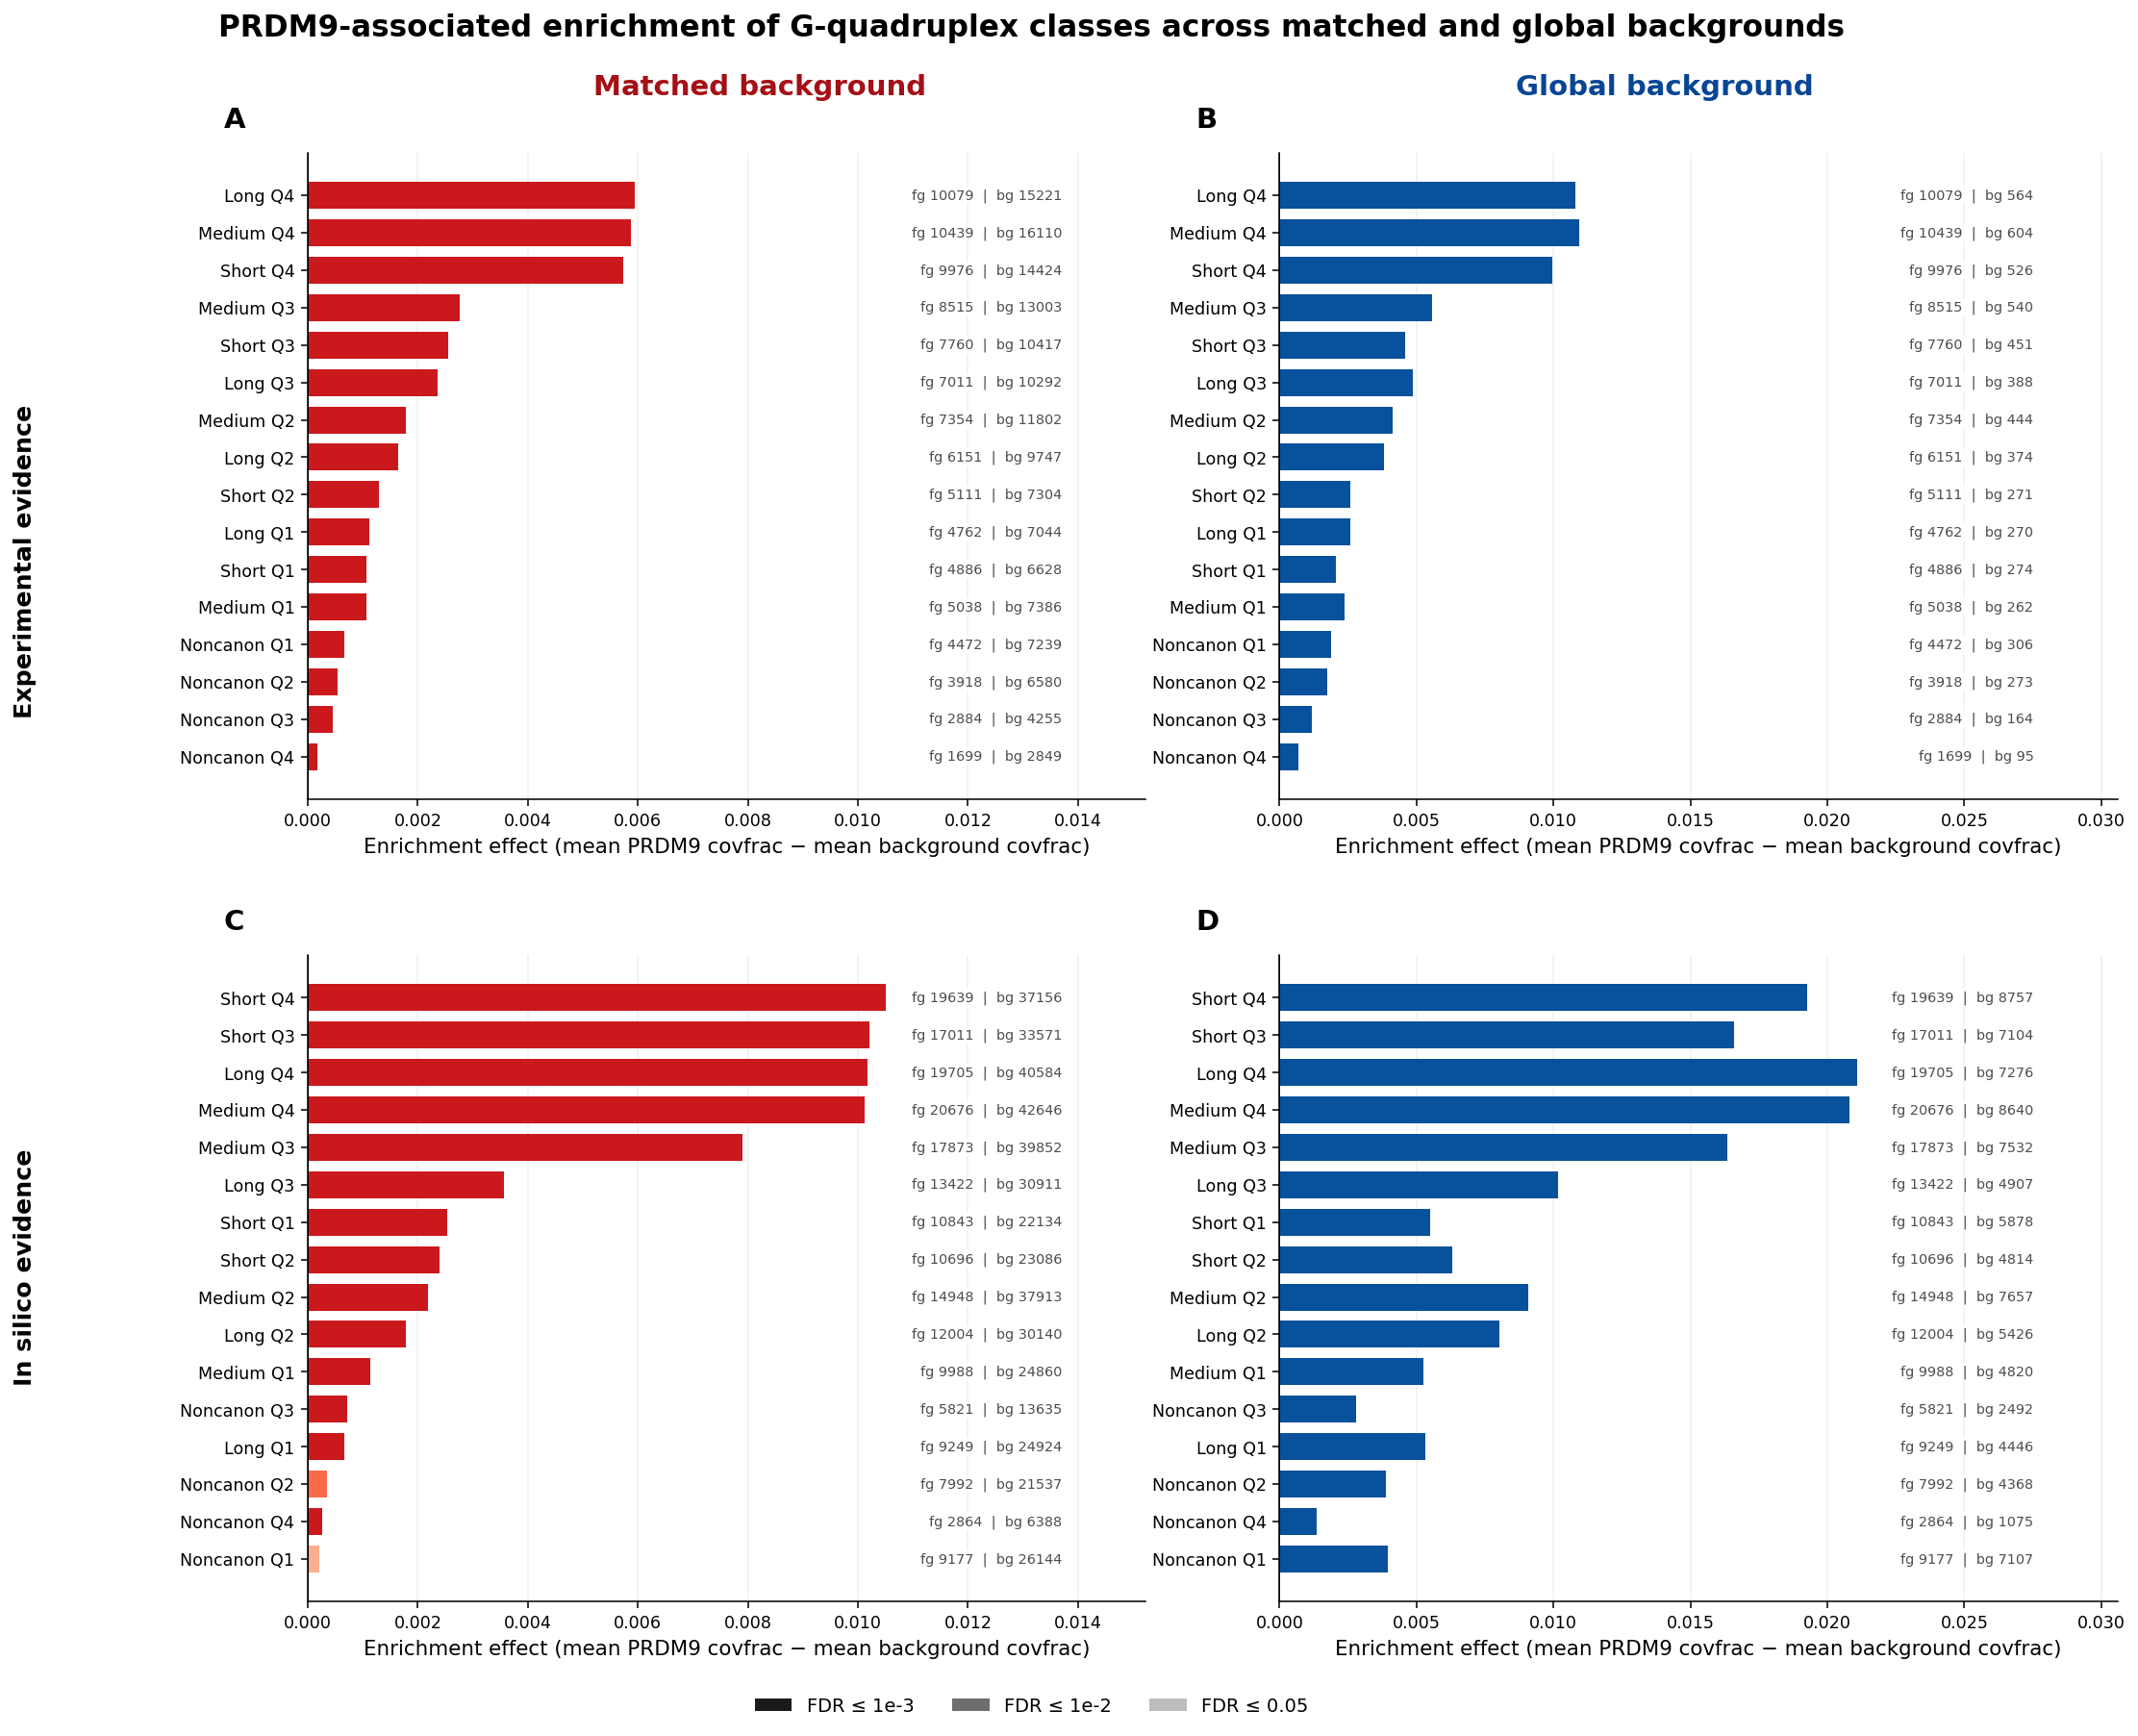

[04/17/26 12:37:12] INFO     Figure written to:                                                                    
                             data_prdm9_g4_enrichment_main_figure_production/figures/Figure_G4_main_2x2_datasetA_vs
                             _datasetB.covfrac_only.png

                    INFO     Figure written to:                                                                    
                             data_prdm9_g4_enrichment_main_figure_production/figures/Figure_G4_main_2x2_datasetA_vs
                             _datasetB.covfrac_only.pdf

In [14]:
# Build publication-style 2×2 main figure
logger.info("[5/6] Building revised 2×2 main figure")

column_specs = [
    ("datasetA_matched", "Matched background (dataset A)"),
    ("datasetB_global", "Global background (dataset B)"),
]
row_specs = [
    ("supported", "Supported G4 loci\n(experimental evidence)"),
    ("unsupported", "Unsupported G4 loci\n(in silico only)"),
]


def pretty_group_label(group: str) -> str:
    base, q = group.rsplit("_", 1)
    pretty_base = {
        "short": "Short",
        "medium": "Medium",
        "long": "Long",
        "noncanon": "Noncanon",
    }.get(base, base.replace("_", " ").title())
    return f"{pretty_base} {q.upper()}"


# matched background defines row order; global follows it exactly
order_by_support = {}
for support, _ in row_specs:
    ref = results[
        (results["background_name"] == "datasetA_matched") &
        (results["support"] == support) &
        (results["metric"] == "covfrac")
    ].copy()
    ref["effect_plot"] = np.maximum(ref["effect_mean_diff"].to_numpy(dtype=np.float64), 0.0)
    ref = ref.sort_values(["effect_plot", "group"], ascending=[False, True]).reset_index(drop=True)
    order = ref["group"].tolist()
    order_by_support[support] = order

# x-axis now starts at 0; reserve room on the right for fg/bg callouts
lim_by_bg = {}
for bg_name, _ in column_specs:
    vals = results.loc[
        (results["background_name"] == bg_name) & (results["metric"] == "covfrac"),
        "effect_mean_diff"
    ].to_numpy(dtype=np.float64)
    vmax = float(np.nanmax(np.maximum(vals, 0.0))) if len(vals) else 0.0
    lim_by_bg[bg_name] = max(0.01, vmax * 1.45)

fig = plt.figure(figsize=(16.8, 13.8))
gs = fig.add_gridspec(
    2, 2,
    left=0.18, right=0.98, top=0.90, bottom=0.12,
    wspace=0.16, hspace=0.24,
)

# Column headers
fig.text(0.38, 0.935, "Matched background", ha="center", va="center",
         fontsize=15, fontweight="bold", color=PALETTE["datasetA_matched"]["accent"])
fig.text(0.78, 0.935, "Global background", ha="center", va="center",
         fontsize=15, fontweight="bold", color=PALETTE["datasetB_global"]["accent"])

# Row headers
fig.text(0.055, 0.68, "Experimental evidence", ha="center", va="center",
         fontsize=13, fontweight="bold", rotation=90)
fig.text(0.055, 0.30, "In silico evidence", ha="center", va="center",
         fontsize=13, fontweight="bold", rotation=90)

panel_letter = {(0, 0): "A", (0, 1): "B", (1, 0): "C", (1, 1): "D"}

for row_i, (support, _) in enumerate(row_specs):
    group_order = order_by_support[support]

    for col_i, (bg_name, bg_title) in enumerate(column_specs):
        ax = fig.add_subplot(gs[row_i, col_i])

        sub = results[
            (results["background_name"] == bg_name) &
            (results["support"] == support) &
            (results["metric"] == "covfrac")
        ].copy()

        extra_groups = [g for g in sub["group"].tolist() if g not in group_order]
        full_order = group_order + sorted(extra_groups)
        sub["group"] = pd.Categorical(sub["group"], categories=full_order, ordered=True)
        sub = sub.sort_values("group").reset_index(drop=True)
        sub["effect_plot"] = np.maximum(sub["effect_mean_diff"].to_numpy(dtype=np.float64), 0.0)
        sub["pretty_label"] = sub["group"].astype(str).map(pretty_group_label)

        colors = [dataset_fdr_color(bg_name, fdr) for fdr in sub["fdr_final"].to_numpy()]
        y = np.arange(len(sub))

        ax.barh(
            y,
            sub["effect_plot"].to_numpy(),
            color=colors,
            edgecolor="none",
            height=0.72,
            zorder=2,
        )

        ax.axvline(0.0, color="black", lw=1.0, zorder=3)
        ax.set_yticks(y)
        ax.set_yticklabels(sub["pretty_label"].tolist(), fontsize=9)
        ax.invert_yaxis()
        ax.set_xlabel("Enrichment effect (mean PRDM9 covfrac − mean background covfrac)")
        ax.grid(True, axis="x", alpha=0.18, zorder=1)
        ax.set_xlim(0.0, lim_by_bg[bg_name])

        # panel letter
        ax.text(
            -0.10, 1.03, panel_letter[(row_i, col_i)],
            transform=ax.transAxes, fontsize=15, fontweight="bold",
            ha="left", va="bottom"
        )

        # panel-level annotation box
        # n_fg = int(sub["n_prdm9_total"].iloc[0])
        # n_bg = int(sub["n_bg_total"].iloc[0])
        # n_sig = int((sub["fdr_final"] <= 0.05).sum())
        # ax.text(
        #     0.42, 0.98,
        #     f"FG windows: {n_fg:,}\nBG windows: {n_bg:,}\nFDR ≤ 0.05: {n_sig}/{len(sub)}",
        #     transform=ax.transAxes,
        #     ha="left", va="top",
        #     fontsize=9,
        #     color="#303030",
        #     bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="#D9D9D9", alpha=0.95),
        #     zorder=5,
        # )

        # per-row fg/bg callouts inside the panel, not in the y-axis labels
        x_note = lim_by_bg[bg_name] * 0.9
        for yi, (_, row) in enumerate(sub.iterrows()):
            ax.text(
                x_note, yi,
                f"fg {int(row['wins_pos'])}  |  bg {int(row['wins_bg'])}",
                ha="right", va="center",
                fontsize=7.4,
                color="#4D4D4D",
                bbox=dict(boxstyle="round,pad=0.16", facecolor="white", edgecolor="none", alpha=0.78),
                zorder=4,
                clip_on=False,
            )

# grayscale FDR legend valid for both color families
fdr_handles = [
    Patch(facecolor="#1A1A1A", label="FDR ≤ 1e-3"),
    Patch(facecolor="#6E6E6E", label="FDR ≤ 1e-2"),
    Patch(facecolor="#BDBDBD", label="FDR ≤ 0.05"),
]
fig.legend(
    handles=fdr_handles,
    loc="lower center",
    ncol=3,
    frameon=False,
    bbox_to_anchor=(0.50, 0.05),
    fontsize=10,
)
# fig.text(
#     0.50, 0.082,
#     "Darker shade denotes stronger FDR support in both matched (red) and global (blue) panels.",
#     ha="center", va="center", fontsize=9.5, color="#6A6A6A"
# )

fig.suptitle(
    "PRDM9-associated enrichment of G-quadruplex classes across matched and global backgrounds",
    fontsize=16, fontweight="bold", y=0.975,
)

fig.savefig(FIG_PNG, bbox_inches="tight")
fig.savefig(FIG_PDF, bbox_inches="tight")
plt.show()
logger.info(f"Figure written to: {FIG_PNG}")
logger.info(f"Figure written to: {FIG_PDF}")


In [6]:

# Quick result views and run metadata
logger.info("[6/6] Final summaries")

display_cols = [
    "background_name", "support", "group", "effect_mean_diff",
    "p_mc_bg", "fdr_final", "wins_pos", "wins_bg", "hits_pos", "hits_bg"
]

for bg_name in ["datasetA_matched", "datasetB_global"]:
    for support in ["supported", "unsupported"]:
        sub = results[
            (results["background_name"] == bg_name) &
            (results["support"] == support)
        ].copy()
        print("=" * 110)
        print(f"{bg_name.upper()} | {support.upper()} | COVFRAC")
        display(sub.sort_values("effect_mean_diff", ascending=False)[display_cols].head(16))

meta = {
    "n_workers": int(N_WORKERS),
    "n_iters": int(N_ITERS),
    "chunk_iters": int(CHUNK_ITERS),
    "random_seed": int(RANDOM_SEED),
    "slack_bp": int(SLACK_BP),
    "analysis_metric": "covfrac",
    "statistics": {
        "exact_test": "Welch t-test, two-sided",
        "mc_bg_null": "double-null Monte Carlo over background blocks",
        "mc_pos_null": "double-null Monte Carlo over PRDM9 blocks",
        "fdr_final": "max(BH-FDR_exact, BH-FDR_MC_BG)",
    },
    "input_files": {
        "prdm9_bed": str(PRDM9_BED),
        "datasetA_bed": str(DATASETA_BED),
        "datasetB_bed": str(DATASETB_BED),
        "pqsfinder_bed": str(G4_SCORE_BED),
        "short_track": str(G4_SHORT_TXT),
        "medium_track": str(G4_MEDIUM_TXT),
        "long_track": str(G4_LONG_TXT),
        "experimental_g4_bed": str(G4_EXPERIMENTAL_BED),
        "fasta": str(FASTA_PATH),
    },
    "output_files": {
        "annotated_g4_tsv": str(ANNOTATED_G4_TSV),
        "window_features_datasetA": str(WINDOW_FEATURES_A),
        "window_features_datasetB": str(WINDOW_FEATURES_B),
        "results_tsv": str(RESULTS_TSV),
        "summary_tsv": str(SUMMARY_TSV),
        "figure_png": str(FIG_PNG),
        "figure_pdf": str(FIG_PDF),
    },
}
with open(META_JSON, "w") as f:
    json.dump(meta, f, indent=2)

logger.info(f"Metadata written to: {META_JSON}")
console.print(Panel.fit(
    f"[bold green]Done[/bold green]\n"
    f"Results: {RESULTS_TSV}\n"
    f"Figure: {FIG_PNG}",
    border_style="green"
))


                    INFO     [6/6] Final summaries

DATASETA_MATCHED | SUPPORTED | COVFRAC


,background_name,support,group,effect_mean_diff,p_mc_bg,fdr_final,wins_pos,wins_bg,hits_pos,hits_bg
15,datasetA_matched,supported,long_Q4,0.005942,0.000005,0.000005,10079,15221,26851,27483
14,datasetA_matched,supported,medium_Q4,0.005875,0.000005,0.000005,10439,16110,29470,31367
13,datasetA_matched,supported,short_Q4,0.005739,0.000005,0.000005,9976,14424,26357,25941
12,datasetA_matched,supported,medium_Q3,0.002763,0.000005,0.000005,8515,13003,16446,19304
11,datasetA_matched,supported,short_Q3,0.002550,0.000005,0.000005,7760,10417,13842,14496
10,datasetA_matched,supported,long_Q3,0.002356,0.000005,0.000005,7011,10292,11918,13967
9,datasetA_matched,supported,medium_Q2,0.001786,0.000005,0.000005,7354,11802,12522,16779
8,datasetA_matched,supported,long_Q2,0.001639,0.000005,0.000005,6151,9747,9588,12760
7,datasetA_matched,supported,short_Q2,0.001299,0.000005,0.000005,5111,7304,7289,8966
6,datasetA_matched,supported,long_Q1,0.001113,0.000005,0.000005,4762,7044,6562,8524


DATASETA_MATCHED | UNSUPPORTED | COVFRAC


,background_name,support,group,effect_mean_diff,p_mc_bg,fdr_final,wins_pos,wins_bg,hits_pos,hits_bg
31,datasetA_matched,unsupported,short_Q4,0.010503,0.000005,0.000006,19639,37156,41815,59630
30,datasetA_matched,unsupported,short_Q3,0.010210,0.000005,0.000006,17011,33571,38619,51735
29,datasetA_matched,unsupported,long_Q4,0.010178,0.000005,0.000006,19705,40584,44156,67964
28,datasetA_matched,unsupported,medium_Q4,0.010121,0.000005,0.000006,20676,42646,46188,72782
27,datasetA_matched,unsupported,medium_Q3,0.007911,0.000005,0.000006,17873,39852,36934,63574
26,datasetA_matched,unsupported,long_Q3,0.003561,0.000005,0.000006,13422,30911,20685,42851
25,datasetA_matched,unsupported,short_Q1,0.002535,0.000005,0.000006,10843,22134,15300,27800
24,datasetA_matched,unsupported,short_Q2,0.002401,0.000005,0.000006,10696,23086,14655,29998
23,datasetA_matched,unsupported,medium_Q2,0.002189,0.000005,0.000006,14948,37913,23640,57213
22,datasetA_matched,unsupported,long_Q2,0.001788,0.000005,0.000006,12004,30140,17255,42613


DATASETB_GLOBAL | SUPPORTED | COVFRAC


,background_name,support,group,effect_mean_diff,p_mc_bg,fdr_final,wins_pos,wins_bg,hits_pos,hits_bg
47,datasetB_global,supported,medium_Q4,0.010952,0.000005,0.000005,10439,604,29470,924
46,datasetB_global,supported,long_Q4,0.010797,0.000005,0.000005,10079,564,26851,813
45,datasetB_global,supported,short_Q4,0.009965,0.000005,0.000005,9976,526,26357,790
44,datasetB_global,supported,medium_Q3,0.005552,0.000005,0.000005,8515,540,16446,692
43,datasetB_global,supported,long_Q3,0.004859,0.000005,0.000005,7011,388,11918,479
42,datasetB_global,supported,short_Q3,0.004592,0.000005,0.000005,7760,451,13842,546
41,datasetB_global,supported,medium_Q2,0.004134,0.000005,0.000005,7354,444,12522,538
40,datasetB_global,supported,long_Q2,0.003823,0.000005,0.000005,6151,374,9588,433
39,datasetB_global,supported,long_Q1,0.002572,0.000005,0.000005,4762,270,6562,300
38,datasetB_global,supported,short_Q2,0.002571,0.000005,0.000005,5111,271,7289,295


DATASETB_GLOBAL | UNSUPPORTED | COVFRAC


,background_name,support,group,effect_mean_diff,p_mc_bg,fdr_final,wins_pos,wins_bg,hits_pos,hits_bg
63,datasetB_global,unsupported,long_Q4,0.021096,0.000005,0.000005,19705,7276,44156,8231
62,datasetB_global,unsupported,medium_Q4,0.020798,0.000005,0.000005,20676,8640,46188,9923
61,datasetB_global,unsupported,short_Q4,0.019270,0.000005,0.000005,19639,8757,41815,9860
60,datasetB_global,unsupported,short_Q3,0.016583,0.000005,0.000005,17011,7104,38619,8055
59,datasetB_global,unsupported,medium_Q3,0.016345,0.000005,0.000005,17873,7532,36934,8568
58,datasetB_global,unsupported,long_Q3,0.010173,0.000005,0.000005,13422,4907,20685,5331
57,datasetB_global,unsupported,medium_Q2,0.009094,0.000005,0.000005,14948,7657,23640,8565
56,datasetB_global,unsupported,long_Q2,0.008030,0.000005,0.000005,12004,5426,17255,5865
55,datasetB_global,unsupported,short_Q2,0.006310,0.000005,0.000005,10696,4814,14655,5134
54,datasetB_global,unsupported,short_Q1,0.005496,0.000005,0.000005,10843,5878,15300,6302


                    INFO     Metadata written to:                                                                  
                             data_prdm9_g4_enrichment_main_figure_production/metadata/run_metadata.json

╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ Done                                                                                                            │
│ Results:                                                                                                        │
│ data_prdm9_g4_enrichment_main_figure_production/tables/g4seq_oldstyle_covfrac_enrichment.datasetA_vs_datasetB.t │
│ sv                                                                                                              │
│ Figure:                                                                                                         │
│ data_prdm9_g4_enrichment_main_figure_production/figures/Figure_G4_main_2x2_datasetA_vs_datasetB.covfrac_only.pn │
│ g                                                                                                               │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯